## import the important libraries

In [265]:
import numpy as np
print(np.__version__)
import pandas as pd
print(pd.__version__)
import matplotlib
print(matplotlib.__version__)
import matplotlib.pyplot as plt
import seaborn as sns
print(sns.__version__)

2.4.4
3.0.2
3.10.8
0.13.2


## Read Dataset

In [266]:
ds = pd.read_csv(r'E:\Datasets\netflix_titles\netflix_titles.csv')

## Explore Dataset

In [267]:
print(ds.head())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [268]:
print(ds.tail())

     show_id     type        title         director  \
8802   s8803    Movie       Zodiac    David Fincher   
8803   s8804  TV Show  Zombie Dumb              NaN   
8804   s8805    Movie   Zombieland  Ruben Fleischer   
8805   s8806    Movie         Zoom     Peter Hewitt   
8806   s8807    Movie       Zubaan      Mozez Singh   

                                                   cast        country  \
8802  Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...  United States   
8803                                                NaN            NaN   
8804  Jesse Eisenberg, Woody Harrelson, Emma Stone, ...  United States   
8805  Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...  United States   
8806  Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...          India   

             date_added  release_year rating   duration  \
8802  November 20, 2019          2007      R    158 min   
8803       July 1, 2019          2018  TV-Y7  2 Seasons   
8804   November 1, 2019          2009      R   

In [269]:
print(ds.dtypes)

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


In [270]:
print(ds.shape)

(8807, 12)


In [271]:
print(ds.columns)

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')


In [272]:
print(ds.index)

RangeIndex(start=0, stop=8807, step=1)


In [273]:
duplicated_rows = ds.duplicated()
answer = "Yes, There are duplicated rows" if duplicated_rows.any() else "NO, there's not any duplicated row"
print(answer)

NO, there's not any duplicated row


In [274]:
null_values = ds.isnull()
answer = "Yes, There are null values" if null_values.any().any() else "NO, there's not any null value"
print(answer)
print(null_values.sum())

Yes, There are null values
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


## Clean Data

### date_added

In [275]:
print(ds['date_added'])
ds['date_added'] = pd.to_datetime(ds['date_added'].str.strip())
print(ds['date_added'])

0       September 25, 2021
1       September 24, 2021
2       September 24, 2021
3       September 24, 2021
4       September 24, 2021
               ...        
8802     November 20, 2019
8803          July 1, 2019
8804      November 1, 2019
8805      January 11, 2020
8806         March 2, 2019
Name: date_added, Length: 8807, dtype: str
0      2021-09-25
1      2021-09-24
2      2021-09-24
3      2021-09-24
4      2021-09-24
          ...    
8802   2019-11-20
8803   2019-07-01
8804   2019-11-01
8805   2020-01-11
8806   2019-03-02
Name: date_added, Length: 8807, dtype: datetime64[us]


In [276]:
print(ds['date_added'].dtype)

datetime64[us]


### duration

In [277]:
print(ds['duration'].head())
ds['duration'] = ds['duration'].str.extract(r'(\d+)').astype(float)
print(ds['duration'].head())

0       90 min
1    2 Seasons
2     1 Season
3     1 Season
4    2 Seasons
Name: duration, dtype: str
0    90.0
1     2.0
2     1.0
3     1.0
4     2.0
Name: duration, dtype: float64


## type

In [278]:
print(ds['type'].head())
conditions = [ds['type'] == 'Movie', ds['type'] == 'TV Show']
choices = [0, 1]
ds['type'] = np.select(conditions, choices)
print(ds['type'].head())

0      Movie
1    TV Show
2    TV Show
3    TV Show
4    TV Show
Name: type, dtype: str
0    0
1    1
2    1
3    1
4    1
Name: type, dtype: int64


## Explore Dataset after cleaning

In [279]:
print(ds.head())

  show_id  type                  title         director  \
0      s1     0   Dick Johnson Is Dead  Kirsten Johnson   
1      s2     1          Blood & Water              NaN   
2      s3     1              Ganglands  Julien Leclercq   
3      s4     1  Jailbirds New Orleans              NaN   
4      s5     1           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

  date_added  release_year rating  duration  \
0 2021-09-25          2020  PG-13      90.0   
1 2021-09-24          2021  TV-MA       2.0   
2 2021-09-24          2021  TV-MA       1.0   
3 2021-09-24          2021  TV

In [280]:
print(ds.dtypes)

show_id                    str
type                     int64
title                      str
director                   str
cast                       str
country                    str
date_added      datetime64[us]
release_year             int64
rating                     str
duration               float64
listed_in                  str
description                str
dtype: object


## Data Analyses

### General Overview
#### General Overview
- How many titles are on Netflix?
#### How many are Movies vs TV Shows?
- Count
- Percentage
- Visualization (Pie chart & Bar chart)
#### How has Netflix's content grown over time?
- Use:
    - date_added
    - release_year
- Questions:
    - How many titles were added each year?
    - Which year had the largest increase?
- Visualization: Line chart

In [281]:
print(ds['title'].count())

8807


Movies    6131
Shows     2676
Name: count, dtype: int64
Movies    69.615079
Shows     30.384921
Name: count, dtype: float64


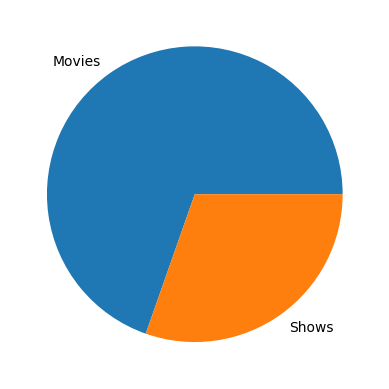

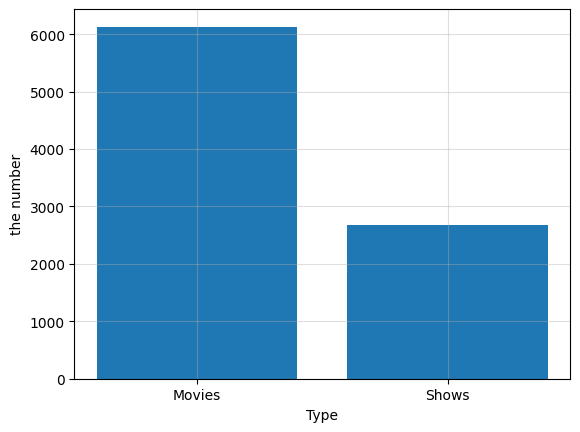

In [282]:
count = ds['type'].value_counts().sort_index()
count.index = ['Movies', 'Shows']
print(count)


percentage = (count/count.sum())*100
print(percentage)

plt.pie(count, labels=count.index)
plt.show()
plt.bar(count.index, count)
plt.grid(alpha = 0.4)
plt.xlabel('Type')
plt.ylabel('the number')
plt.show()

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
Name: title, dtype: int64
2017.0 759.0


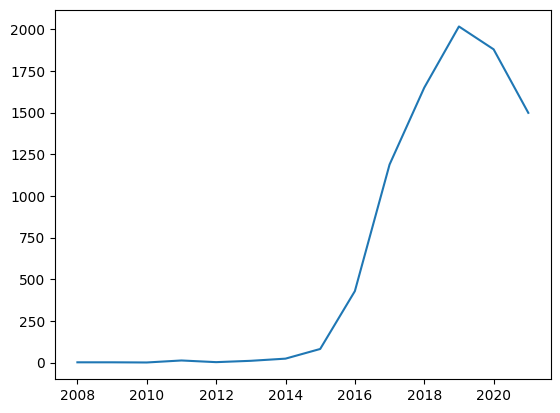

In [283]:
ds['year_added'] = ds['date_added'].dt.year
titles = ds.groupby('year_added')['title'].count()
print(titles)

growth = titles.diff()
print(growth.idxmax(), growth.max())
plt.plot(titles.index , titles)
plt.show()

### Movies Analysis
#### What is the distribution of movie durations?
- Questions:
    - Average duration
    - Median
    - Longest movie
    - Shortest movie

- Visualization: Histogram

#### Which movies are the longest?
- Top 10 longest movies.

99.57718668407311
98.0
Black Mirror: Bandersnatch 312.0
Silent 3.0


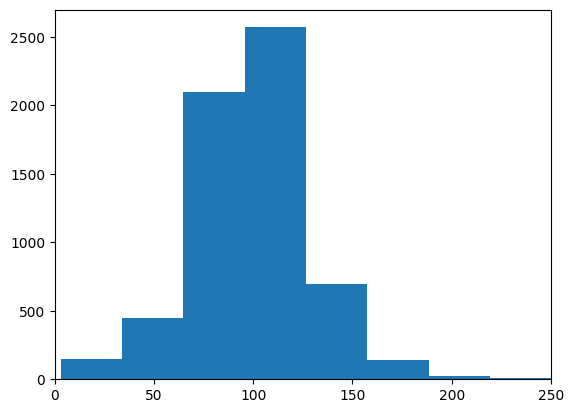

title
Black Mirror: Bandersnatch     312.0
Headspace: Unwind Your Mind    273.0
The School of Mischief         253.0
No Longer kids                 237.0
Lock Your Girls In             233.0
Raya and Sakina                230.0
Once Upon a Time in America    229.0
Sangam                         228.0
Lagaan                         224.0
Jodhaa Akbar                   214.0
Name: duration, dtype: float64


In [284]:
movies = ds[ds['type'] == 0].copy()
movies.index = movies['title']
average = movies['duration'].mean()
print(average)
median = movies['duration'].median()
print(median)
duration = movies['duration']
print(duration.idxmax(), duration.max())
print(duration.idxmin(), duration.min())
plt.hist(movies['duration'])
plt.xlim(0, 250)
plt.show()

top10 = movies['duration'].nlargest(10)
print(top10)

### TV Shows Analysis
#### How many seasons do TV Shows usually have?
- Questions:
    - Average number of seasons
    - Maximum seasons
    - Distribution
- Visualization: Histogram
#### Which TV Shows have the most seasons?
- Top 10.

1.764947683109118
----------
Grey's Anatomy 17.0
----------


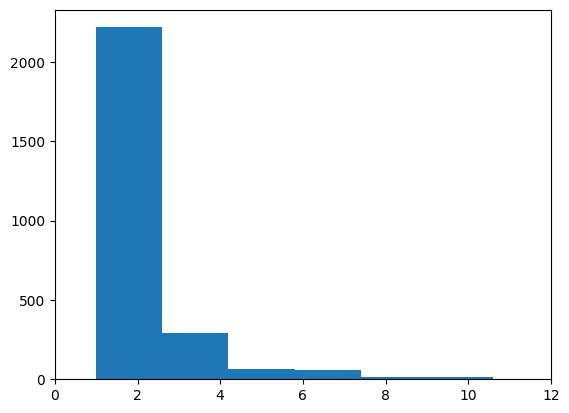

----------
title
Grey's Anatomy            17.0
Supernatural              15.0
NCIS                      15.0
Heartland                 13.0
COMEDIANS of the world    13.0
Red vs. Blue              13.0
Trailer Park Boys         12.0
Criminal Minds            12.0
Cheers                    11.0
Frasier                   11.0
Name: duration, dtype: float64


In [285]:
sessions = ds[ds['type'] ==  1].copy()
duration = sessions['duration']
duration.index = sessions['title']

average = duration.mean()
print(average)

print('-' * 10)

print(duration.idxmax(), duration.max())

print('-' * 10)

plt.hist(duration)
plt.xlim(0, 12)
plt.show()

print('-' * 10)

top10 = duration.nlargest(10)
print(top10)

### Release Trends
#### How many titles were released each year?
- Use: release_year
- Questions:
    - Which years produced the most content?
    - Is Netflix focusing more on recent content?
- Visualization: Line chart

#### Difference between release year and added year
- Questions:
    - How long does Netflix usually wait before adding content?

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
        ... 
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: title, Length: 74, dtype: int64
--------------------------------------------------
2018 1147
--------------------------------------------------
0        1.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
8802    12.0
8803     1.0
8804    10.0
8805    14.0
8806     4.0
Name: lag, Length: 8807, dtype: float64


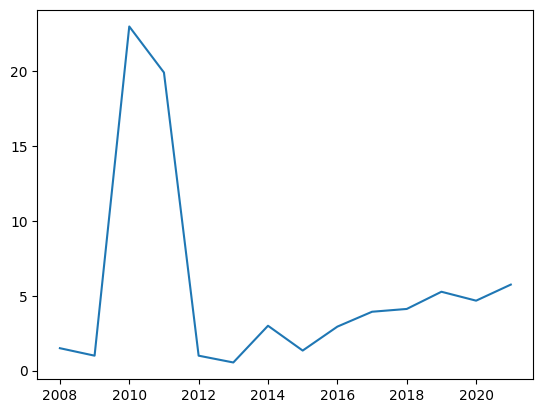

--------------------------------------------------
4.688416505626918


In [286]:
release = ds.groupby('release_year')
titles = release['title'].count()
print(titles)

print('-' * 50)

print(titles.idxmax(), titles.max())

print('-' * 50)

ds['lag'] = ds['year_added'] - ds['release_year']
print(ds['lag'])
release_years = ds.groupby('year_added')['lag'].mean()
plt.plot(release_years.index, release_years)
plt.show()

print('-' * 50)

print(ds['lag'].mean())

### Country Analysis
- Which countries produce the most recent Netflix content?
    - Need to split countries because many rows contain multiple countries.
- Which countries mostly produce Movies?
- Which countries mostly produce TV Shows?
- Which countries have the longest movies?
    - Average movie duration by country.

In [287]:
ds_with_counteries_split = ds.assign(country = ds['country'].str.split(', ')).explode('country')
average_date_content_for_each_country = ds_with_counteries_split.groupby('country')['lag'].mean()
top15_recent_content_for_each_country = average_date_content_for_each_country.nsmallest(15)
print(top15_recent_content_for_each_country.index)


only_movies = ds_with_counteries_split[ds_with_counteries_split['type'] == 0]
most_movies = only_movies.groupby('country').size()
print(most_movies.nlargest(10))

only_shows = ds_with_counteries_split[ds_with_counteries_split['type'] == 1]
most_shows = only_shows.groupby('country').size()
print(most_shows.nlargest(10))

only_movies = ds_with_counteries_split[ds_with_counteries_split['type'] == 0]
average_movies_duration = only_movies.groupby('country')['duration'].mean()
print(average_movies_duration.nlargest(10))

Index(['Albania', 'Angola', 'Armenia', 'Bermuda', 'Cayman Islands', 'Cuba',
       'Ecuador', 'Georgia', 'Kazakhstan', 'Malawi', 'Mauritius', 'Mongolia',
       'Samoa', 'Uganda', 'United States,'],
      dtype='str', name='country')
country
United States     2751
India              962
United Kingdom     532
Canada             319
France             303
Germany            182
Spain              171
Japan              119
China              114
Mexico             111
dtype: int64
country
United States     938
United Kingdom    272
Japan             199
South Korea       170
Canada            126
France             90
India              84
Taiwan             70
Australia          66
Spain              61
dtype: int64
country
Liechtenstein    200.000000
Montenegro       157.000000
Soviet Union     156.666667
Bahamas          145.000000
Cameroon         143.000000
Morocco          137.333333
Malta            135.500000
India            125.912682
Burkina Faso     125.000000
Ethiopia      

### Genre Analysis
- Split listed_in.
- Questions:
    - What are the most common genres?
        - Example: Drama, Comedy, Documentary, Kids, Horror
        - Visualization: Horizontal bar chart.
    - Which genres are growing over time?
        - Genre vs Year
        - Heatmap
    - Which genres are mostly Movies?
    - Which genres are mostly TV Shows?

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
dtype: int64


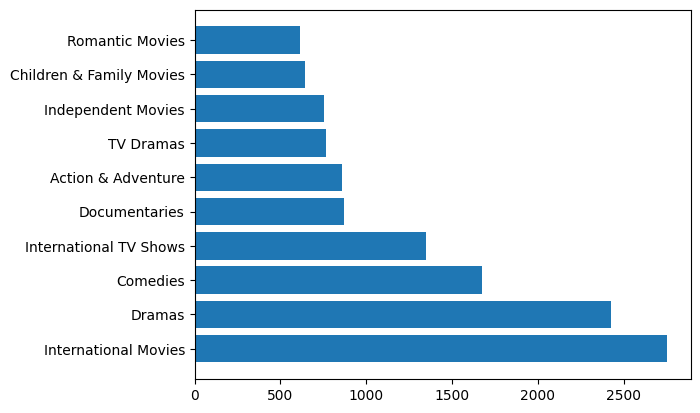

--------------------------------------------------


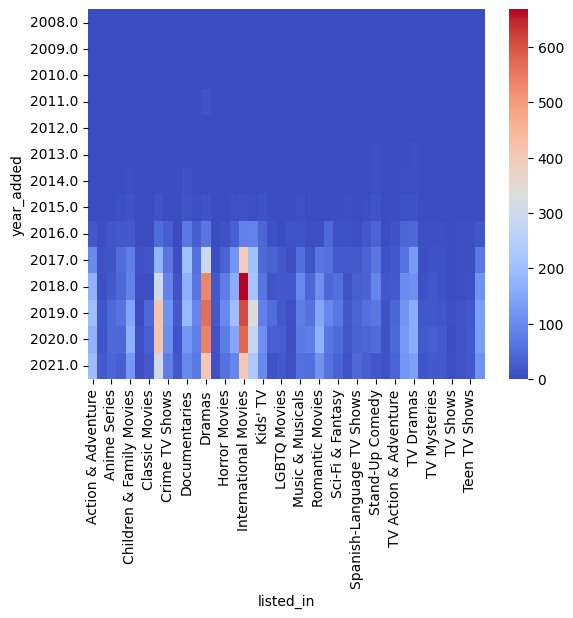

In [288]:
genre_split = ds.assign(listed_in = ds['listed_in'].str.split(', ')).explode('listed_in')
genre_groups = genre_split.groupby('listed_in').size()
most_common = genre_groups.nlargest(10)
print(most_common)
plt.barh(most_common.index, most_common)
plt.show()

print('-' * 50)

genres_over_time = genre_split.groupby(['year_added', 'listed_in']).size()
heatmap_data = genres_over_time.unstack(level = 1, fill_value=0)
sns.heatmap(heatmap_data, cmap='coolwarm')
plt.show()

In [289]:
genre_split = ds.assign(listed_in = ds['listed_in'].str.split(', ')).explode('listed_in')
movies = genre_split[genre_split['type'] == 0]
count_movies = movies.groupby('listed_in').size()
top10_movies = count_movies.nlargest(10)
print(top10_movies)

print('-' * 50)

genre_split = ds.assign(listed_in = ds['listed_in'].str.split(', ')).explode('listed_in')
shows = genre_split[genre_split['type'] == 1]
count_shows = shows.groupby('listed_in').size()
top10_shows = count_shows.nlargest(10)
print(top10_shows)

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
Documentaries                869
Action & Adventure           859
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Thrillers                    577
Music & Musicals             375
dtype: int64
--------------------------------------------------
listed_in
International TV Shows    1351
TV Dramas                  763
TV Comedies                581
Crime TV Shows             470
Kids' TV                   451
Docuseries                 395
Romantic TV Shows          370
Reality TV                 255
British TV Shows           253
Anime Series               176
dtype: int64


### Ratings Analysis
- Which ratings are most common?
    - Examples: TV-MA, TV-14, PG, PG-13, R
    - Visualization: Bar chart
- Ratings by content type
    - Cross-tab:
        - Movie vs Rating
        - TV Show vs Rating
- Which genres receive mature ratings most often?

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
dtype: int64
--------------------------------------------------


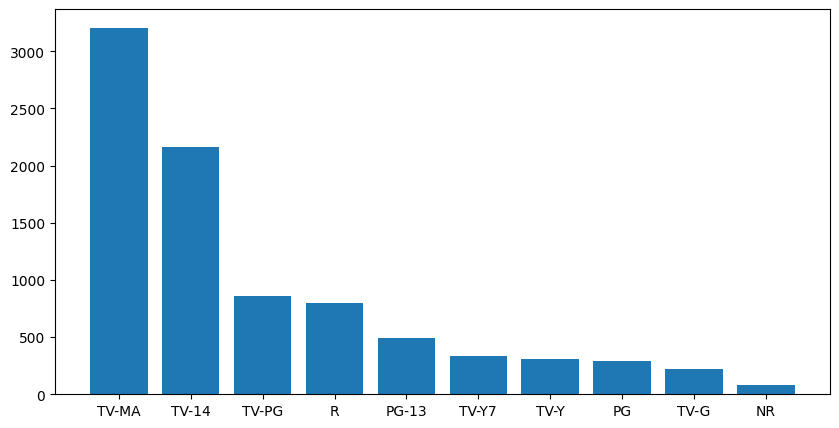

In [290]:
ratings = ds.groupby('rating').size().nlargest(10)
print(ratings)
print('-' * 50)
plt.figure(figsize=(10, 5))
plt.bar(ratings.index, ratings)
plt.show()

In [291]:
# Solve the ploblem of assigning duration to rating
# we need to move these values from rating to duration again
mask = ds['rating'].str.contains('min', na = False)
print(ds.loc[mask, ['duration', 'rating']])
ds.loc[mask, 'duration'] = ds.loc[mask, 'rating'].str.extract(r'(\d+)').astype(float).values.flatten()
ds.loc[mask, 'rating'] = np.nan
print(ds.loc[mask, ['duration', 'rating']])

      duration  rating
5541       NaN  74 min
5794       NaN  84 min
5813       NaN  66 min
      duration rating
5541      74.0    NaN
5794      84.0    NaN
5813      66.0    NaN


In [292]:
movies = ds[ds['type'] == 0]
cross_tab = pd.crosstab(movies['type'], movies['rating'])
print(cross_tab)

tv_shows = ds[ds['type'] == 1]
cross_tab = pd.crosstab(tv_shows['type'], tv_shows['rating'])
print(cross_tab)

rating   G  NC-17  NR   PG  PG-13    R  TV-14  TV-G  TV-MA  TV-PG  TV-Y  \
type                                                                      
0       41      3  75  287    490  797   1427   126   2062    540   131   

rating  TV-Y7  TV-Y7-FV  UR  
type                         
0         139         5   3  
rating  NR  R  TV-14  TV-G  TV-MA  TV-PG  TV-Y  TV-Y7  TV-Y7-FV
type                                                           
1        5  2    733    94   1145    323   176    195         1


In [293]:
# Matures: (movies: R & NC-17), (movies: TV-MA)
mature_movies = ds[(ds['type'] == 0) & (ds['rating'].isin(['R', 'NC-17']))]
print(f'movies: {mature_movies.shape[0]}')
mature_tvShows = ds[(ds['type'] == 1) & (ds['rating'] == 'TV-MA')]
print(f'TV Shows: {mature_tvShows.shape[0]}')

movies: 800
TV Shows: 1145


### Director Analysis
- Which directors have the most titles?
    - Top 15 directors.
- Which directors only make Movies?
- Which directors only make TV Shows?

In [294]:
directors = ds.groupby('director')
Top15_directors = directors.size().nlargest(15)
print(Top15_directors)

print('-' * 50)

split_directors = ds.assign(director = ds['director'].str.split(', ')).explode('director')
movies_directors = split_directors[split_directors['type'] == 0]['director'].drop_duplicates()
Tv_Shows_directors = split_directors[split_directors['type'] == 1]['director'].drop_duplicates()
only_movies_directors = movies_directors[~movies_directors.isin(Tv_Shows_directors)]
only_Tv_Shows_directors = Tv_Shows_directors[~Tv_Shows_directors.isin(movies_directors)]
print(only_movies_directors)
print('-' * 50)
print(only_Tv_Shows_directors)

director
Rajiv Chilaka             19
Raúl Campos, Jan Suter    18
Marcus Raboy              16
Suhas Kadav               16
Jay Karas                 14
Cathy Garcia-Molina       13
Jay Chapman               12
Martin Scorsese           12
Youssef Chahine           12
Steven Spielberg          11
Don Michael Paul          10
David Dhawan               9
Fernando Ayllón            8
Hakan Algül                8
Johnnie To                 8
dtype: int64
--------------------------------------------------
0               Kirsten Johnson
6                 Robert Cullen
6                José Luis Ucha
7                  Haile Gerima
9                Theodore Melfi
                 ...           
8792                     Mu Chu
8798    Chandra Prakash Dwivedi
8801            Majid Al Ansari
8805               Peter Hewitt
8806                Mozez Singh
Name: director, Length: 4694, dtype: str
--------------------------------------------------
8              Andy Devonshire
11           Kong

### Cast Analysis
- Split cast.
- Questions:
    - Which actors appear most often?
        - Top 20 actors.
    - Which actor appears in both Movies and TV Shows?
    - Which actors frequently work together?
        - (Co-occurrence analysis)

In [295]:
split_cast = ds.assign(cast = ds['cast'].str.split(', ')).explode('cast')
casts_ordered = split_cast['cast'].value_counts()
top20 = casts_ordered.iloc[0:20]
print(top20)

print('-' * 50)

movies_casts = split_cast[split_cast['type'] == 0]['cast'].drop_duplicates()
Tv_shows_casts = split_cast[split_cast['type'] == 1]['cast'].drop_duplicates()
movies_shows_cast = movies_casts[movies_casts.isin(Tv_shows_casts)]
print(movies_shows_cast)

print('-' * 50)

merged = split_cast.merge(split_cast, on = 'show_id')
frequent_pairs = merged[merged['cast_x'] < merged['cast_y']]
actor_pairs = frequent_pairs.groupby(['cast_x', 'cast_y']).size()
most_actions = actor_pairs.nlargest(10)
print(most_actions)

cast
Anupam Kher          43
Shah Rukh Khan       35
Julie Tejwani        33
Naseeruddin Shah     32
Takahiro Sakurai     32
Rupa Bhimani         31
Akshay Kumar         30
Om Puri              30
Yuki Kaji            29
Amitabh Bachchan     28
Paresh Rawal         28
Boman Irani          27
Rajesh Kava          26
Vincent Tong         26
Andrea Libman        25
Kareena Kapoor       25
Samuel L. Jackson    24
John Cleese          24
Jigna Bhardwaj       23
Fred Tatasciore      23
Name: count, dtype: int64
--------------------------------------------------
0                     NaN
6            Kimiko Glenn
6           James Marsden
6               Ken Jeong
6       Elizabeth Perkins
              ...        
8781    Brent Pendergrass
8782        Austin Butler
8784       Eileen Stevens
8784           H.D. Quinn
8787         Persia White
Name: cast, Length: 4376, dtype: str
--------------------------------------------------
cast_x          cast_y       
Julie Tejwani   Rupa Bhimani     3

### Time Analysis
- Using date_added
- Which month has Netflix added the most content?
    - Visualization: Monthly bar chart
- Which weekday has the most additions? Monday, Tuesday, ...etc.
- Has Netflix become more active in recent years?
    - Titles added per month/year.

0        9.0
1        9.0
2        9.0
3        9.0
4        9.0
        ... 
8802    11.0
8803     7.0
8804    11.0
8805     1.0
8806     3.0
Name: month_added, Length: 8807, dtype: float64
month_added
1.0     738
2.0     563
3.0     742
4.0     764
5.0     632
6.0     728
7.0     827
8.0     755
9.0     770
10.0    760
11.0    705
12.0    813
dtype: int64


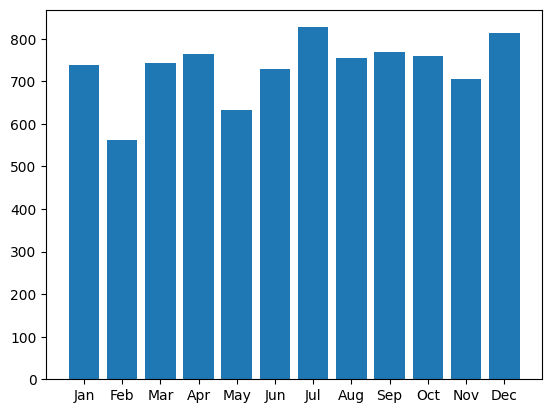

In [296]:
copy_ds = ds.copy()
copy_ds['month_added'] = copy_ds['date_added'].dt.month
print(copy_ds['month_added'])
months = copy_ds.groupby('month_added').size()
print(months)
months.index = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.bar(months.index, months)
plt.show()

year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.0    1879
2021.0    1498
dtype: int64


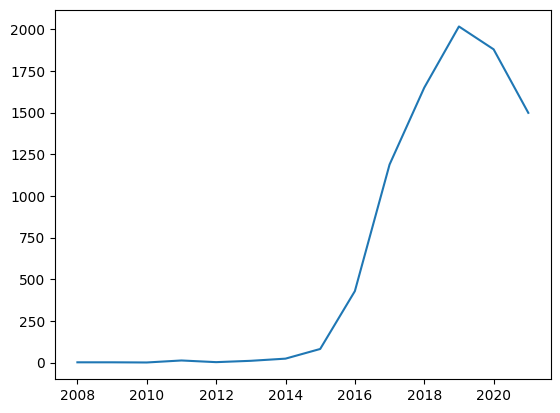

In [306]:
years = ds.groupby('year_added').size()
print(years)
plt.plot(years.index, years)
plt.show()

### Missing Data Analysis
- Which columns have the most missing values?
    - Visualization: Missing value bar chart.
- Are missing directors more common for TV Shows?
- Are missing countries associated with certain genres?

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             7
duration           0
listed_in          0
description        0
year_added        10
lag               10
dtype: int64


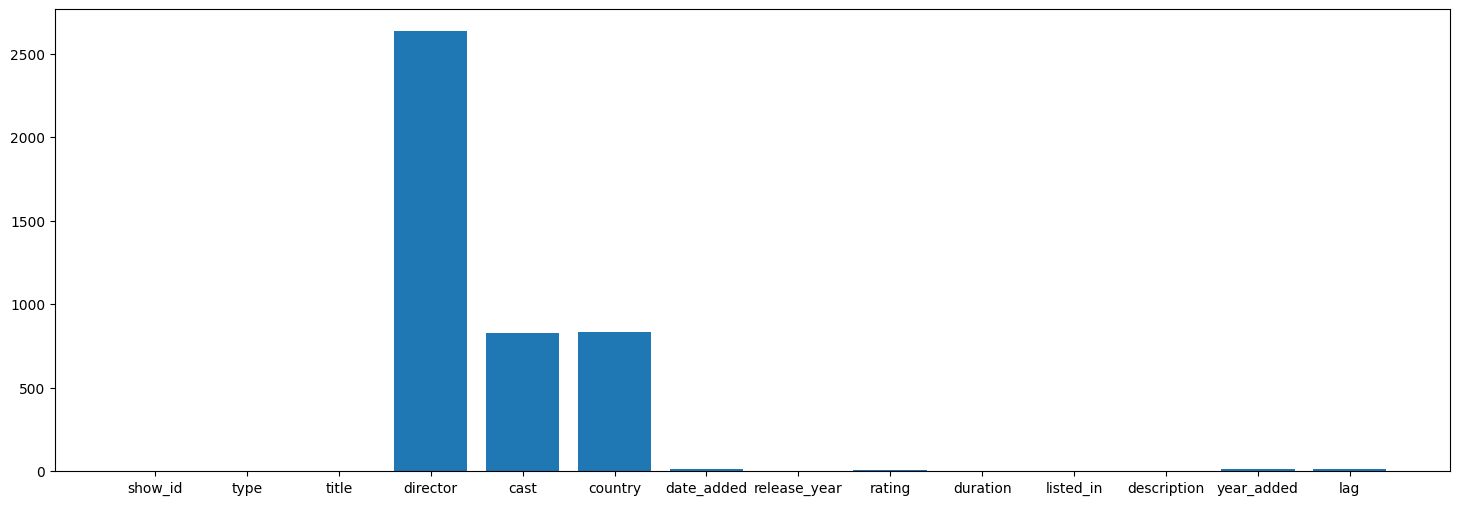

--------------------------------------------------
Yes
--------------------------------------------------
listed_in
Action & Adventure                                              1
Action & Adventure, Anime Features                              1
Action & Adventure, Anime Features, Children & Family Movies    0
Action & Adventure, Anime Features, Classic Movies              1
Action & Adventure, Anime Features, Horror Movies               0
                                                               ..
TV Horror, TV Mysteries, Teen TV Shows                          0
TV Horror, Teen TV Shows                                        0
TV Sci-Fi & Fantasy, TV Thrillers                               0
TV Shows                                                        7
Thrillers                                                       3
Name: country, Length: 514, dtype: int64


In [319]:
missing_values = ds.isna().sum()
print(missing_values)
plt.figure(figsize=(18, 6))
plt.bar(missing_values.index, missing_values)
plt.show()

print('-' * 50)

missing_values_Movies = ds[ds['type'] == 0]['director'].isna().sum()
missing_values_TV_Show = ds[ds['type'] == 1]['director'].isna().sum()
answer = 'No' if missing_values_Movies > missing_values_TV_Show else 'Yes'
print(answer)

print('-' * 50)

countries = ds.groupby('listed_in')['country']
missing_countries = countries.apply(lambda country: country.isna().sum())
print(missing_countries)